# AISE 4010 — Traffic Forecasting | Stage 1



## 1. Load and audit the dataset
The original source has no timestamp column. Hourly row order is used as supplied by the project source.

In [ ]:
# Import file utilities, numerical tools, plotting, preprocessing, and neural-network libraries.
from pathlib import Path
import json
import time
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import joblib

# Use a fixed random seed to make model initialization and training more reproducible.
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Look for the original traffic file
paths = [Path('traffic.txt')]
source_path = next((p for p in paths if p.exists()), None)
if source_path is None:
    raise FileNotFoundError('Place traffic.txt or traffic.txt.gz next to this notebook or inside data/.')

# The dataset has no header row; assign each of its sensor columns a descriptive name.
df = pd.read_csv(source_path, header=None, compression='infer')
df.columns = [f'sensor_{i}' for i in range(df.shape[1])]
# Use row positions; the raw file does not include authenticated timestamps.
df.index.name = 'hour_index'

# Audit the dataset before modeling: dimensions, missing readings, and repeated rows.
print('Source:', source_path)
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('Hourly sampling is assumed from dataset description; calendar start unverified.')
display(df.head())

Source: traffic.txt.gz
Shape: (17544, 862)
Missing values: 0
Duplicate rows: 14
Hourly sampling is assumed from dataset description; calendar start unverified.


,sensor_0,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,...,sensor_852,sensor_853,sensor_854,sensor_855,sensor_856,sensor_857,sensor_858,sensor_859,sensor_860,sensor_861
hour_index,,,,,,,,,,,,,,,,,,,,,
0,0.0048,0.0146,0.0289,0.0142,0.0064,0.0232,0.0162,0.0242,0.0341,0.0375,...,0.0051,0.0051,0.0074,0.0079,0.0051,0.0051,0.0339,0.0051,0.0100,0.0121
1,0.0072,0.0148,0.0350,0.0174,0.0084,0.0240,0.0201,0.0338,0.0434,0.0381,...,0.0036,0.0036,0.0107,0.0058,0.0036,0.0036,0.0348,0.0036,0.0087,0.0136
2,0.0040,0.0101,0.0267,0.0124,0.0049,0.0170,0.0127,0.0255,0.0332,0.0309,...,0.0030,0.0030,0.0043,0.0050,0.0030,0.0030,0.0327,0.0030,0.0061,0.0107
3,0.0039,0.0060,0.0218,0.0090,0.0029,0.0118,0.0088,0.0163,0.0211,0.0199,...,0.0033,0.0033,0.0019,0.0052,0.0033,0.0033,0.0292,0.0033,0.0040,0.0071
4,0.0042,0.0055,0.0191,0.0082,0.0024,0.0095,0.0064,0.0087,0.0144,0.0226,...,0.0049,0.0049,0.0011,0.0071,0.0049,0.0049,0.0264,0.0049,0.0040,0.0039


In [ ]:
# Original draft's target options, plus sensor summary
# Forecast one sensor using its previous 24 readings to predict the next hourly reading.
TARGET = 'sensor_10'
LOOKBACK = 24
HORIZON = 1

# Keep the alternative exploratory targets from the original draft for comparison.
series = df[TARGET].astype('float32')
y_mean = df.mean(axis=1)
subset = df.iloc[:, :20]

# Identify sensors with little variation or many zero values: both may affect forecasts.
stats = df.describe().T
print('Lowest-variation sensors:')
display(stats[['mean','std','max']].sort_values('std').head(10))
print('Highest fractions of zeros:')
display((df == 0).mean().sort_values(ascending=False).head(10))
print('Chosen target:', TARGET, '| mean:', float(series.mean()), '| std:', float(series.std()))

Lowest-variation sensors:


,mean,std,max
sensor_751,0.013380,0.010980,0.1067
sensor_753,0.016327,0.011063,0.2637
sensor_752,0.016952,0.011622,0.1213
sensor_750,0.018291,0.012051,0.2986
sensor_735,0.026443,0.012676,0.1427
sensor_80,0.031990,0.012985,0.1884
sensor_853,0.021159,0.013271,0.0876
sensor_852,0.017752,0.013580,0.1226
sensor_302,0.024323,0.013734,0.0767
sensor_181,0.021406,0.013930,0.0527


Highest fractions of zeros:


,0
sensor_751,0.145520
sensor_722,0.120611
sensor_716,0.115823
sensor_825,0.110237
sensor_351,0.109097
sensor_718,0.103454
sensor_402,0.099407
sensor_444,0.090971
sensor_181,0.088748
sensor_73,0.087608


Chosen target: sensor_10 | mean: 0.042895857244729996 | std: 0.03464429825544357


In [ ]:
# Two exploratory plots for Stage 1
# Plot a one-week snapshot to reveal short-term changes and a histogram for distribution/zeros.
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
axes[0].plot(series.iloc[:168].to_numpy())
axes[0].set(title=f'EDA Figure 1 — First 168 hourly samples of {TARGET}', xlabel='Hourly sample', ylabel='Sensor reading')
axes[1].hist(series.to_numpy(), bins=50)
axes[1].set(title=f'EDA Figure 2 — Distribution of {TARGET}', xlabel='Sensor reading', ylabel='Count')
plt.tight_layout()
plt.show()

## 2. Chronological split and training-only standardization
60% training, 20% validation, 20% held-out test. Inputs and outputs from each split stay within that split.

In [ ]:
# Chronological split: the earliest 60% trains, next 20% validates, final 20% is held out.
# Never shuffle rows globally in time-series forecasting.
n = len(series)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

train = series.iloc[:train_end]
val = series.iloc[train_end:val_end]
test = series.iloc[val_end:]

print('Split rows:', {'train': len(train), 'validation': len(val), 'test': len(test)})
print('Boundaries:', {'train': (0,train_end-1),
                     'validation': (train_end,val_end-1), 'test': (val_end,n-1)})

# Fit standardization parameters (mean and standard deviation) on training data ONLY.
# Reusing that fitted scaler for validation/test prevents data leakage.
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1)).astype('float32')
val_scaled = scaler.transform(val.to_numpy().reshape(-1, 1)).astype('float32')
test_scaled = scaler.transform(test.to_numpy().reshape(-1, 1)).astype('float32')
print('Training scaled mean / std:', train_scaled.mean(), train_scaled.std())

Split rows: {'train': 10526, 'validation': 3509, 'test': 3509}
Boundaries: {'train': (0, 10525), 'validation': (10526, 14034), 'test': (14035, 17543)}
Training scaled mean / std: -4.3488853e-09 1.0


In [ ]:
# Convert continuous readings to supervised examples: 24 historical points -> 1 future target.
# X has shape (samples, lookback, features); y has shape (samples,).
def create_windows(data, lookback=24, horizon=1):
    X, y = [], []
    # Only produce windows where both the full lookback and target are available.
    for i in range(len(data) - lookback - horizon + 1):
        X.append(data[i:i + lookback])
        # For horizon=1, the label is the reading immediately after the window.
        y.append(data[i + lookback + horizon - 1, 0])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

# Window each split independently; no validation/test target is used as a training label.
# This discards the first LOOKBACK+HORIZON-1 possible targets per split.
X_train, y_train = create_windows(train_scaled, LOOKBACK, HORIZON)
X_val, y_val = create_windows(val_scaled, LOOKBACK, HORIZON)
X_test, y_test = create_windows(test_scaled, LOOKBACK, HORIZON)
for name, X, y in [('train', X_train, y_train), ('validation', X_val, y_val), ('test (reserved)', X_test, y_test)]:
    print(name, X.shape, y.shape)
print('First training input:', X_train[0, :, 0])
print('First next-hour target:', y_train[0])

train (10502, 24, 1) (10502,)
validation (3485, 24, 1) (3485,)
test (reserved) (3485, 24, 1) (3485,)
First training input: [-0.80799544 -0.7553242  -0.87237144 -1.0040495  -1.0684255  -1.0391637
 -0.9601568  -0.92211646 -0.89285463 -0.44222277  0.40051734  0.41222206
  0.38003406 -0.1817927   0.03767087  0.5994976   0.32443666 -0.14082614
 -0.19349742 -0.24909483 -0.41003478 -0.5358606  -0.65290785 -0.87237144]
First next-hour target: -0.9455259


## 3. Baseline models and consistent metrics
All validation MAE/RMSE values are reported on the **original sensor scale**, using the scaler fitted on training data.

In [ ]:
# Undo standardization so MAE/RMSE are interpretable in the sensor's original units.
def evaluate_model(y_true, y_pred, fitted_scaler):
    true_original = fitted_scaler.inverse_transform(np.asarray(y_true).reshape(-1,1)).ravel()
    pred_original = fitted_scaler.inverse_transform(np.asarray(y_pred).reshape(-1,1)).ravel()
    return (mean_absolute_error(true_original, pred_original),
            np.sqrt(mean_squared_error(true_original, pred_original)))

# Persistence assumes the next reading equals the most recently observed reading.
def persistence_baseline(X):
    return X[:, -1, 0]

# Moving average predicts the mean of all readings within the input window.
def moving_average_baseline(X):
    return np.mean(X[:, :, 0], axis=1)

# Evaluate both baselines on identical validation windows for a fair comparison.
pred_persistence = persistence_baseline(X_val)
pred_moving_avg = moving_average_baseline(X_val)
persistence_mae, persistence_rmse = evaluate_model(y_val, pred_persistence, scaler)
moving_mae, moving_rmse = evaluate_model(y_val, pred_moving_avg, scaler)

# Parameter and fit-time counts are zero for these simple, non-trained baselines.
baseline_results = pd.DataFrame([
    {'Model':'Persistence', 'MAE':persistence_mae, 'RMSE':persistence_rmse, 'Parameters':0, 'Training Time (s)':0.0},
    {'Model':'Moving Average', 'MAE':moving_mae, 'RMSE':moving_rmse, 'Parameters':0, 'Training Time (s)':0.0}
])
display(baseline_results)

,Model,MAE,RMSE,Parameters,Training Time (s)
0,Persistence,0.013278,0.024765,0,0.0
1,Moving Average,0.024108,0.033898,0,0.0


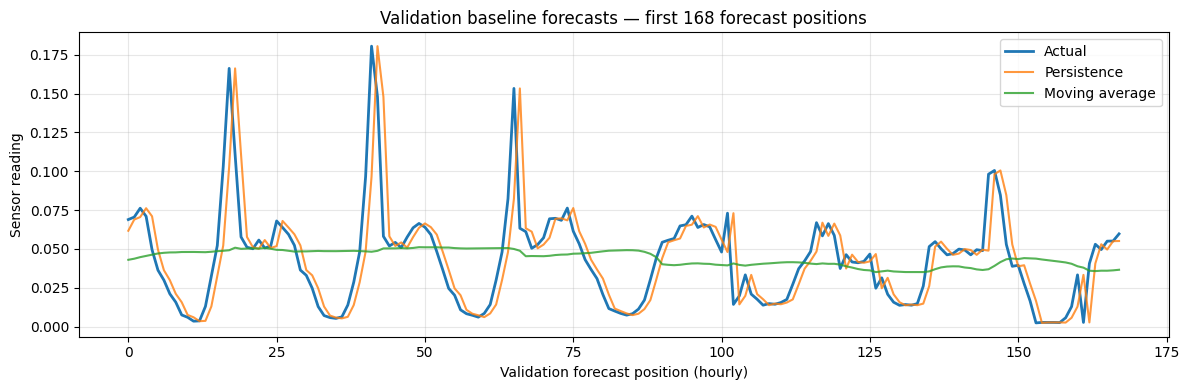

In [ ]:
# Compare the baseline trajectories with actual validation readings in original units.
actual_original = scaler.inverse_transform(y_val.reshape(-1,1)).ravel()
persistence_original = scaler.inverse_transform(pred_persistence.reshape(-1,1)).ravel()
moving_original = scaler.inverse_transform(pred_moving_avg.reshape(-1,1)).ravel()
n_plot = min(168, len(y_val))
plt.figure(figsize=(12,4))
plt.plot(actual_original[:n_plot], label='Actual', linewidth=2)
plt.plot(persistence_original[:n_plot], label='Persistence', alpha=.8)
plt.plot(moving_original[:n_plot], label='Moving average', alpha=.8)
plt.title('Validation baseline forecasts — first 168 forecast positions')
plt.xlabel('Validation forecast position (hourly)'); plt.ylabel('Sensor reading')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 4. MLP forecasting model

In [ ]:
# MLPs need flattened feature vectors rather than 3D temporal tensors.
X_train_mlp = X_train.reshape(X_train.shape[0], -1)
X_val_mlp = X_val.reshape(X_val.shape[0], -1)
tf.keras.utils.set_random_seed(SEED)
# Two fully connected hidden layers learn nonlinear relations in recent traffic.
# Dropout randomly disables some activations during training to limit overfitting.
mlp = Sequential([
    Input(shape=(LOOKBACK,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1)
])
# Regression output is linear (one value); MSE is the optimization loss.
mlp.compile(optimizer='adam', loss='mse', metrics=['mae'])
mlp.summary()

# Time the training run; stop when validation loss has not improved for 10 epochs.
# The best observed weights are restored before evaluating the model.
start = time.perf_counter()
history_mlp = mlp.fit(
    X_train_mlp, y_train, validation_data=(X_val_mlp, y_val),
    epochs=100, batch_size=64, shuffle=False, verbose=1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)]
)
mlp_training_time = time.perf_counter() - start
# Predict only the validation set during model development; leave final test untouched.
pred_mlp = mlp.predict(X_val_mlp, verbose=0).ravel()
mlp_mae, mlp_rmse = evaluate_model(y_val, pred_mlp, scaler)
print('MLP:', {'MAE':mlp_mae, 'RMSE':mlp_rmse, 'parameters':mlp.count_params(), 'training_seconds':mlp_training_time})

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,713 (14.50 KB)

 Trainable params: 3,713 (14.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.4506 - mae: 0.4208 - val_loss: 0.2819 - val_mae: 0.2873
Epoch 2/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2873 - mae: 0.3180 - val_loss: 0.2408 - val_mae: 0.2648
Epoch 3/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2474 - mae: 0.2924 - val_loss: 0.2131 - val_mae: 0.2439
Epoch 4/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2195 - mae: 0.2774 - val_loss: 0.2056 - val_mae: 0.2329
Epoch 5/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2043 - mae: 0.2645 - val_loss: 0.1982 - val_mae: 0.2262
Epoch 6/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1992 - mae: 0.2613 - val_loss: 0.1975 - val_mae: 0.2242
Epoch 7/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1919 - mae: 0.2543 - val_loss: 0.1926 - val_mae: 0.2197
Epoch 8/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1849 - mae: 0.2485 - val_loss: 0.1914 - val_mae: 0.2220
Epoch 9/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/

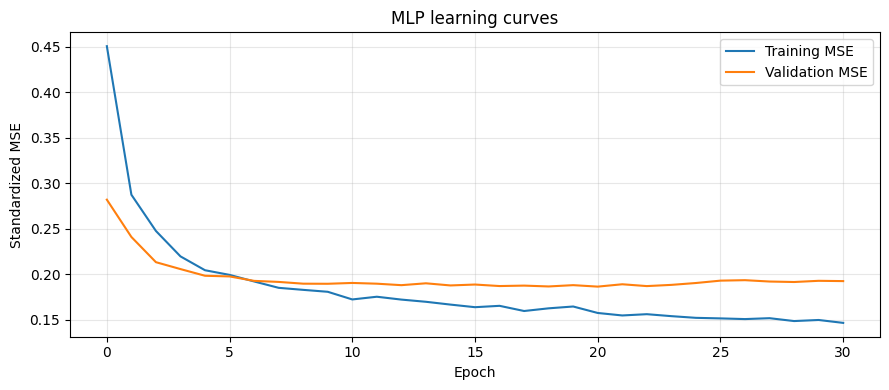

In [ ]:
# Diverging train/validation loss can indicate overfitting.
plt.figure(figsize=(9,4))
plt.plot(history_mlp.history['loss'], label='Training MSE')
plt.plot(history_mlp.history['val_loss'], label='Validation MSE')
plt.title('MLP learning curves'); plt.xlabel('Epoch'); plt.ylabel('Standardized MSE')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 5. CNN forecasting model

In [ ]:
tf.keras.utils.set_random_seed(SEED)
# CNN keeps the temporal dimension and learns local patterns through 1D filters.
# Pooling shortens the feature sequence; Dense(1) makes a numeric forecast.
cnn = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Conv1D(32, 3, activation='relu'),
    MaxPooling1D(2),
    Conv1D(64, 3, activation='relu'),
    Flatten(),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1)
])
cnn.compile(optimizer='adam', loss='mse', metrics=['mae'])
cnn.summary()
# Use the same validation split, max epochs, batch size, and early-stopping rule as MLP.
start = time.perf_counter()
history_cnn = cnn.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=100, batch_size=64, shuffle=False, verbose=1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)]
)
cnn_training_time = time.perf_counter() - start
# Evaluate the untuned CNN in the original sensor units for comparison.
pred_cnn = cnn.predict(X_val, verbose=0).ravel()
cnn_mae, cnn_rmse = evaluate_model(y_val, pred_cnn, scaler)
print('CNN:', {'MAE':cnn_mae, 'RMSE':cnn_rmse, 'parameters':cnn.count_params(), 'training_seconds':cnn_training_time})

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 22, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 11, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 9, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,833 (97.00 KB)

 Trainable params: 24,833 (97.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.4299 - mae: 0.3982 - val_loss: 0.2661 - val_mae: 0.2890
Epoch 2/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2398 - mae: 0.2982 - val_loss: 0.2182 - val_mae: 0.2447
Epoch 3/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2162 - mae: 0.2776 - val_loss: 0.2082 - val_mae: 0.2319
Epoch 4/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2039 - mae: 0.2635 - val_loss: 0.2014 - val_mae: 0.2312
Epoch 5/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1934 - mae: 0.2567 - val_loss: 0.1969 - val_mae: 0.2176
Epoch 6/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1892 - mae: 0.2525 - val_loss: 0.1910 - val_mae: 0.2192
Epoch 7/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1826 - mae: 0.2479 - val_loss: 0.1872 - val_mae: 0.2145
Epoch 8/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1792 - mae: 0.2446 - val_loss: 0.1870 - val_mae: 0.2155
Epoch 9/100
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/

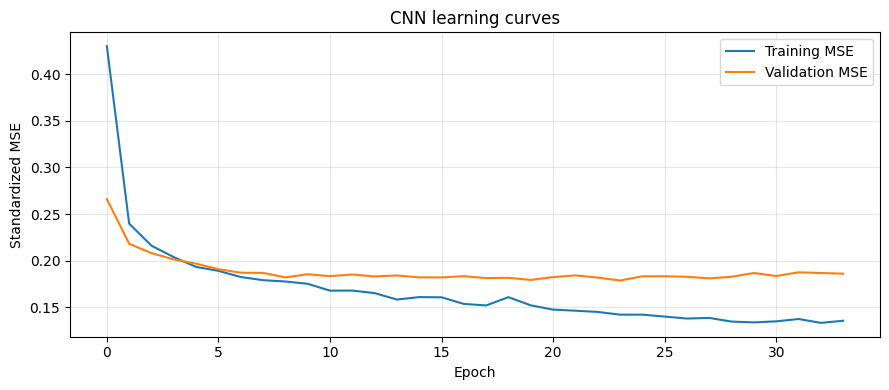

In [ ]:
# Track whether extra epochs help validation performance or only improve training fit.
plt.figure(figsize=(9,4))
plt.plot(history_cnn.history['loss'], label='Training MSE')
plt.plot(history_cnn.history['val_loss'], label='Validation MSE')
plt.title('CNN learning curves'); plt.xlabel('Epoch'); plt.ylabel('Standardized MSE')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 6. CNN grid search (validation only)
8 combinations: filters {16,32} × kernel size {3,5} × learning rate {0.001,0.0005}. Objective: minimum validation MAE. Save best model immediately; this avoids accidentally losing its weights when clearing Keras state.

In [ ]:
# Factory function rebuilds a fresh CNN for each grid-search configuration.
def build_cnn(filters, kernel_size, learning_rate):
    model = Sequential([
        Input(shape=(LOOKBACK,1)),
        Conv1D(filters, kernel_size, activation='relu'),
        MaxPooling1D(2),
        Conv1D(filters * 2, 3, activation='relu'),
        Flatten(),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mse', metrics=['mae'])
    return model

# Eight combinations: 2 filter choices × 2 kernel widths × 2 learning rates.
# All choices are evaluated on the same validation set, never the test set.
param_grid = {'filters':[16,32], 'kernel_size':[3,5], 'learning_rate':[0.001,0.0005]}
# Save the winning CNN immediately whenever validation MAE improves.
artifacts = Path('artifacts'); artifacts.mkdir(exist_ok=True)
best_path = artifacts / 'best_stage1_cnn.keras'
grid_results = []
best_val_mae = np.inf
best_config = None

# Train every configuration with the same budget and fixed seed.
for filters, kernel_size, lr in product(param_grid['filters'], param_grid['kernel_size'], param_grid['learning_rate']):
    # Release stale Keras graph state and reset the seed for this trial.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_cnn(filters, kernel_size, lr)
    start = time.perf_counter()
    history = model.fit(
        X_train, y_train, validation_data=(X_val, y_val),
        epochs=50, batch_size=64, shuffle=False, verbose=0,
        callbacks=[EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)]
    )
    elapsed = time.perf_counter() - start
    pred = model.predict(X_val, verbose=0).ravel()
    # Convert predictions to original units; validation MAE decides the winner.
    val_mae, val_rmse = evaluate_model(y_val, pred, scaler)
    config = {'filters':filters, 'kernel_size':kernel_size, 'learning_rate':lr}
    grid_results.append({**config, 'MAE':val_mae, 'RMSE':val_rmse,
                         'Parameters':model.count_params(), 'Epochs':len(history.history['loss']),
                         'Training Time (s)':elapsed})
    print(config, 'validation MAE:', round(val_mae, 5))
    # Save NOW, since later iterations clear model sessions and replace model.
    if val_mae < best_val_mae:
        best_val_mae = val_mae
        best_config = config.copy()
        model.save(best_path)

# Sort trial results and reload the actual saved best-performing model.
grid_df = pd.DataFrame(grid_results).sort_values('MAE').reset_index(drop=True)
best_cnn = tf.keras.models.load_model(best_path)
print('Best configuration:', best_config)
display(grid_df)
print('Total grid-search training seconds:', grid_df['Training Time (s)'].sum())

{'filters': 16, 'kernel_size': 3, 'learning_rate': 0.001} validation MAE: 0.00703
{'filters': 16, 'kernel_size': 3, 'learning_rate': 0.0005} validation MAE: 0.00707
{'filters': 16, 'kernel_size': 5, 'learning_rate': 0.001} validation MAE: 0.00717
{'filters': 16, 'kernel_size': 5, 'learning_rate': 0.0005} validation MAE: 0.00714
{'filters': 32, 'kernel_size': 3, 'learning_rate': 0.001} validation MAE: 0.00702
{'filters': 32, 'kernel_size': 3, 'learning_rate': 0.0005} validation MAE: 0.0071
{'filters': 32, 'kernel_size': 5, 'learning_rate': 0.001} validation MAE: 0.00691
{'filters': 32, 'kernel_size': 5, 'learning_rate': 0.0005} validation MAE: 0.00688
Best configuration: {'filters': 32, 'kernel_size': 5, 'learning_rate': 0.0005}


,filters,kernel_size,learning_rate,MAE,RMSE,Parameters,Epochs,Training Time (s)
0,32,5,0.0005,0.006884,0.014388,22849,40,37.757720
1,32,5,0.0010,0.006910,0.014358,22849,35,33.754744
2,32,3,0.0010,0.007018,0.014452,24833,31,31.185489
3,16,3,0.0010,0.007030,0.014479,10913,42,34.966891
4,16,3,0.0005,0.007071,0.014572,10913,50,37.853595
5,32,3,0.0005,0.007102,0.014381,24833,31,29.010403
6,16,5,0.0005,0.007143,0.014488,9921,48,36.311100
7,16,5,0.0010,0.007166,0.014265,9921,38,29.117931


Total grid-search training seconds: 269.95787262300007


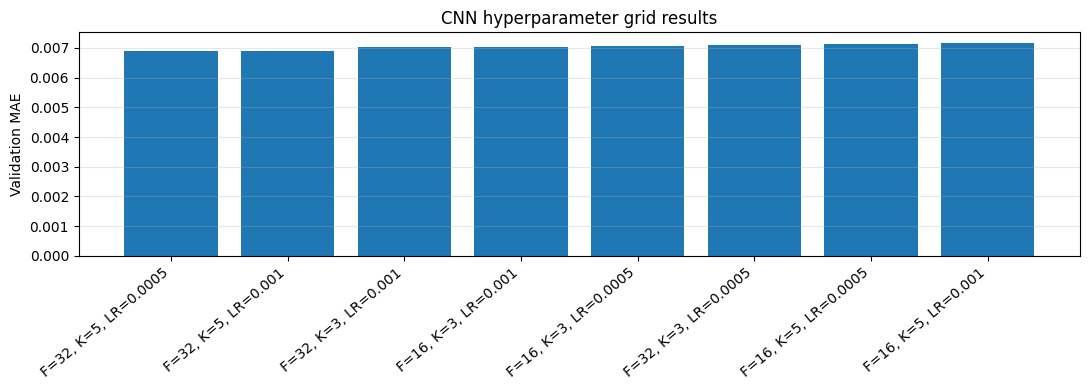

In [ ]:
# Plot each configuration's validation MAE to show the HPO evidence during the demo.
labels = [f"F={int(r.filters)}, K={int(r.kernel_size)}, LR={r.learning_rate}" for r in grid_df.itertuples()]
plt.figure(figsize=(11,4))
plt.bar(range(len(grid_df)), grid_df['MAE'])
plt.xticks(range(len(labels)), labels, rotation=40, ha='right')
plt.ylabel('Validation MAE'); plt.title('CNN hyperparameter grid results')
plt.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()

## 7. Stage 1 model comparison and saved artifacts

VALIDATION-ONLY RESULTS (not final test results)


,Model,MAE,RMSE,Parameters,Training Time (s),Improvement over Persistence (%)
0,CNN (Grid Search),0.006884,0.014388,22849,37.757720,48.158500
1,CNN,0.007018,0.014452,24833,35.330215,47.143980
2,MLP,0.007198,0.014749,3713,18.068406,45.789368
3,Persistence,0.013278,0.024765,0,0.000000,0.000000
4,Moving Average,0.024108,0.033898,0,0.000000,-81.562512


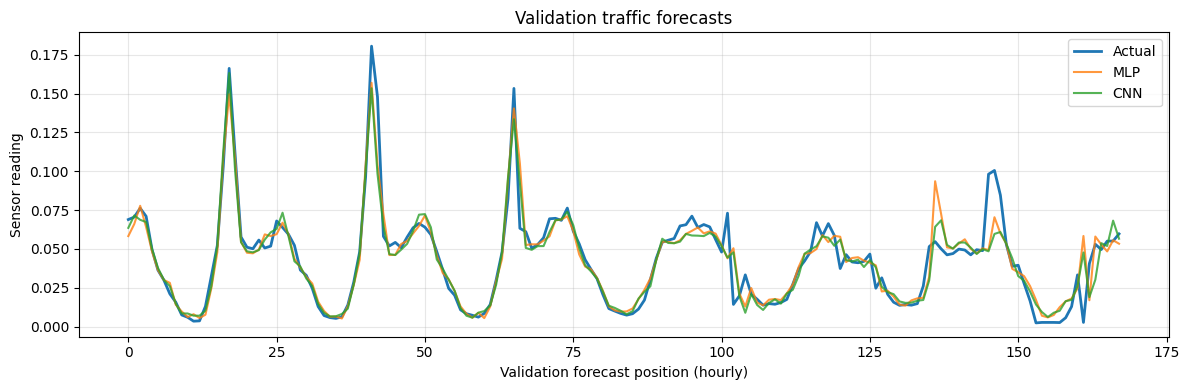

In [ ]:
# Re-evaluate the selected checkpoint on validation (not final test).
best_predictions = best_cnn.predict(X_val, verbose=0).ravel()
best_mae, best_rmse = evaluate_model(y_val, best_predictions, scaler)
winning_time = float(grid_df.iloc[0]['Training Time (s)'])

# Combine baselines, MLP, untuned CNN, and tuned CNN under common metrics.
results = pd.concat([baseline_results, pd.DataFrame([
    {'Model':'MLP', 'MAE':mlp_mae, 'RMSE':mlp_rmse, 'Parameters':mlp.count_params(), 'Training Time (s)':mlp_training_time},
    {'Model':'CNN', 'MAE':cnn_mae, 'RMSE':cnn_rmse, 'Parameters':cnn.count_params(), 'Training Time (s)':cnn_training_time},
    {'Model':'CNN (Grid Search)', 'MAE':best_mae, 'RMSE':best_rmse, 'Parameters':best_cnn.count_params(), 'Training Time (s)':winning_time}
])], ignore_index=True)
# Positive improvement means smaller MAE than the persistence reference.
results['Improvement over Persistence (%)'] = (
    (persistence_mae - results['MAE']) / persistence_mae * 100
    if persistence_mae != 0 else np.nan
)
results = results.sort_values('MAE').reset_index(drop=True)
print('VALIDATION-ONLY RESULTS (not final test results)')
display(results)

# Show where the neural forecasts follow or miss validation-set fluctuations.
mlp_original = scaler.inverse_transform(pred_mlp.reshape(-1,1)).ravel()
cnn_original = scaler.inverse_transform(pred_cnn.reshape(-1,1)).ravel()
plt.figure(figsize=(12,4))
plt.plot(actual_original[:n_plot], label='Actual', linewidth=2)
plt.plot(mlp_original[:n_plot], label='MLP', alpha=.8)
plt.plot(cnn_original[:n_plot], label='CNN', alpha=.8)
plt.title('Validation traffic forecasts'); plt.xlabel('Validation forecast position (hourly)')
plt.ylabel('Sensor reading'); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()